<a href="https://colab.research.google.com/github/ushkgowda/Multi-Domain-Data-Analysis-Portfolio-5-Real--Projects/blob/main/project5_social_media_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 5: Social Media Analytics
**Portfolio: Multi-Domain Data Analysis** | Domain: Social media / marketing

**Goals:** analyze engagement metrics, audience behavior and content performance across Instagram, Facebook, X and LinkedIn, and turn the findings into recommendations.

> **Simulated data.** No real account export was supplied, so the CSVs come from a seeded generator (`generate_data.py`, seed 7). Effects of format, platform, hashtags, timing, promotion and campaigns were built in, so this notebook demonstrates the method, not real-world findings. Swap in real exports with the same columns to get real results.

**Engagement rate (ER)** = (likes + comments + shares + saves) / reach.

## 1. Setup and loading

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
rng = np.random.default_rng(1)

raw = pd.read_csv("/content/social_media_posts.csv")
fw = pd.read_csv("/content/social_media_followers_weekly.csv", parse_dates=["Week_Start"])
print(raw.shape, fw.shape); raw.head()

(1511, 17) (208, 5)


,Post_ID,Date,Time,Platform,Content_Type,Campaign,Promoted,Hashtag_Count,Caption_Length,Followers_At_Post,Impressions,Reach,Likes,Comments,Shares,Saves,Link_Clicks
0,P10865,2026-04-03,14:44,Instagram,Video,Brand Awareness,No,8.0,105.0,58557,23155,18449,1183,150,277,98,304
1,P11293,2026-10-31,08:59,LinkedIn,Text,Giveaway,No,2.0,110.0,20250,8384,5710,185,77,32,45,141
2,P10622,2026-03-16,13:11,LinkedIn,Carousel,Brand Awareness,No,0.0,178.0,16947,11437,7663,352,35,47,62,234
3,P10647,2026-01-01,19:27,Instagram,Video,No campaign,No,4.0,34.0,54614,34884,30894,5928,760,1315,446,536
4,P11469,2026-03-31,17:10,Facebook,Image,No campaign,No,3.0,226.0,39566,6006,4048,91,10,15,17,31


## 2. Validation and cleaning

In [2]:
print("Missing values:", raw.isnull().sum()[raw.isnull().sum() > 0].to_dict())
print("Exact duplicate rows:", raw.duplicated().sum())
df = raw.drop_duplicates().copy(); df["Date"] = pd.to_datetime(df.Date)
print("Duplicate post IDs after cleaning:", df.Post_ID.duplicated().sum(), "| date range:", df.Date.min().date(), "to", df.Date.max().date())
num = ["Impressions", "Reach", "Likes", "Comments", "Shares", "Saves", "Link_Clicks"]
print("Negative values:", int((df[num] < 0).sum().sum()), "| reach > impressions:", int((df.Reach > df.Impressions).sum()), "| zero reach:", int((df.Reach <= 0).sum()))
df["Engagements"] = df.Likes + df.Comments + df.Shares + df.Saves
print("Engagements > reach:", int((df.Engagements > df.Reach).sum()))
print("X saves always zero:", bool((df[df.Platform == "X"].Saves == 0).all()))
print("Max hashtags by platform:", df.groupby("Platform").Hashtag_Count.max().to_dict())

Missing values: {'Time': 18, 'Hashtag_Count': 14, 'Caption_Length': 10}
Exact duplicate rows: 11
Duplicate post IDs after cleaning: 0 | date range: 2025-11-01 to 2026-10-31
Negative values: 0 | reach > impressions: 0 | zero reach: 3
Engagements > reach: 10
X saves always zero: True
Max hashtags by platform: {'Facebook': 15.0, 'Instagram': 15.0, 'LinkedIn': 5.0, 'X': 4.0}


In [3]:
df["Valid"] = (df.Reach > 0) & (df.Engagements <= df.Reach) & (df.Reach <= df.Impressions)
df["ER"] = np.where(df.Valid, df.Engagements / df.Reach.where(df.Reach > 0) * 100, np.nan)
df["CTR"] = np.where(df.Valid, df.Link_Clicks / df.Impressions * 100, np.nan)
df["Hour"] = pd.to_datetime(df.Time, format="%H:%M", errors="coerce").dt.hour
df["Part"] = pd.cut(df.Hour, [-1, 6, 11, 17, 21, 23], labels=["Late night (0-6)", "Morning (7-11)", "Afternoon (12-17)", "Evening (18-21)", "Night (22-23)"])
df["Weekday"] = pd.Categorical(df.Date.dt.day_name(), ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"], ordered=True)
df["Weekend"] = df.Date.dt.dayofweek >= 5; df["Month"] = df.Date.dt.to_period("M").astype(str)
df["Hash_Band"] = pd.cut(df.Hashtag_Count, [-1, 0, 2, 5, 8, 20], labels=["0", "1-2", "3-5", "6-8", "9+"])
df["Cap_Band"] = pd.cut(df.Caption_Length, [0, 60, 150, 300, 2000], labels=["<60", "60-150", "150-300", "300+"])
v = df[df.Valid]; print("Posts:", len(df), "| valid for rate metrics:", len(v))

Posts: 1500 | valid for rate metrics: 1490


Missing values are **not imputed**: a post with a missing hashtag count is simply left out of the hashtag analysis. Invalid rows (zero reach or engagements above reach) are excluded from rate metrics only.

## 3. Overview and skew

Impressions: 32,376,713 | reach: 24,479,976 | engagements: 1,583,965 | clicks: 362,264
Median ER: 3.58% | mean ER: 4.91% | skewness: 3.2 | CTR: 1.12%
Top 10% of posts = 55% of engagements; top 1% = 17%
Median engagements: 281 vs mean 1063


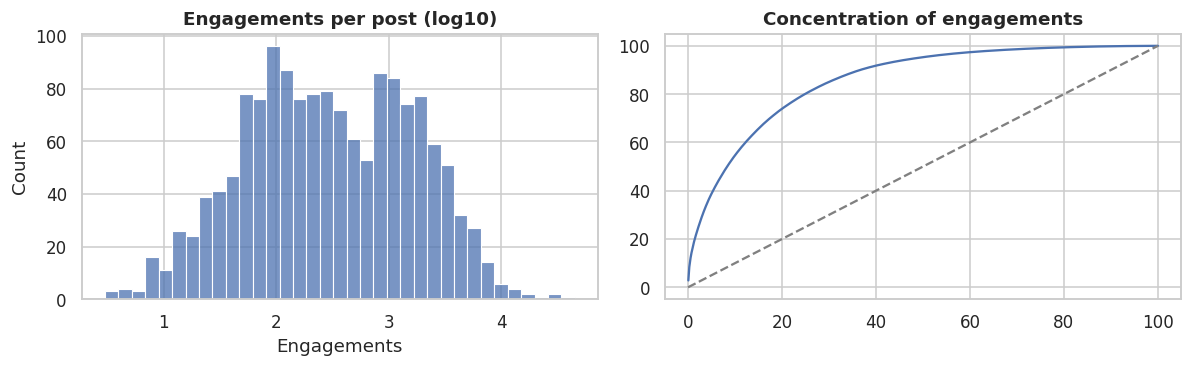

In [4]:
print("Impressions: %s | reach: %s | engagements: %s | clicks: %s" % tuple(f"{x:,.0f}" for x in [df.Impressions.sum(), df.Reach.sum(), v.Engagements.sum(), v.Link_Clicks.sum()]))
print("Median ER: %.2f%% | mean ER: %.2f%% | skewness: %.1f | CTR: %.2f%%" % (v.ER.median(), v.ER.mean(), stats.skew(v.ER), v.Link_Clicks.sum() / v.Impressions.sum() * 100))
s = v.Engagements.sort_values(ascending=False)
print("Top 10%% of posts = %.0f%% of engagements; top 1%% = %.0f%%" % (s.head(int(np.ceil(.1 * len(s)))).sum() / s.sum() * 100, s.head(int(np.ceil(.01 * len(s)))).sum() / s.sum() * 100))
print("Median engagements: %.0f vs mean %.0f" % (v.Engagements.median(), v.Engagements.mean()))
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(np.log10(v.Engagements.clip(lower=1)), bins=35, ax=axs[0]); axs[0].set_title("Engagements per post (log10)")
c = s.cumsum() / s.sum() * 100; axs[1].plot(np.arange(1, len(c) + 1) / len(c) * 100, c.values); axs[1].plot([0, 100], [0, 100], "--", color="grey"); axs[1].set_title("Concentration of engagements")
plt.tight_layout(); plt.show()

In [5]:
def boot_ci(x, n=1000):
    x = np.asarray(x.dropna()); b = [np.median(rng.choice(x, len(x))) for _ in range(n)]; return np.percentile(b, 2.5), np.percentile(b, 97.5)
def seg(data, col):
    g = data[data.Valid].groupby(col, observed=True)
    t = g.agg(posts=("ER", "size"), median_ER=("ER", "median"), median_reach=("Reach", "median"), engagements=("Engagements", "sum"), CTR=("CTR", "median"))
    ci = [boot_ci(data[data.Valid & (data[col] == k)].ER) for k in t.index]; t["CI_low"], t["CI_high"] = [c[0] for c in ci], [c[1] for c in ci]
    t["share_of_engagements_%"] = t.engagements / t.engagements.sum() * 100; return t.round(2)
print("Kruskal-Wallis tests of ER:")
for col in ["Platform", "Content_Type", "Part", "Campaign", "Cap_Band", "Weekday"]:
    print(f"  {col}: p = {stats.kruskal(*[g.ER.values for _, g in v.groupby(col, observed=True)]).pvalue:.1e}")

Kruskal-Wallis tests of ER:
  Platform: p = 2.6e-154
  Content_Type: p = 1.4e-97
  Part: p = 2.1e-05
  Campaign: p = 1.3e-09
  Cap_Band: p = 5.0e-01
  Weekday: p = 1.8e-02


## 4. Platform and content type

,posts,median_ER,median_reach,engagements,CTR,CI_low,CI_high,share_of_engagements_%
Platform,,,,,,,,
Instagram,601,6.01,22037.0,1421536,0.84,5.67,6.36,89.75
Facebook,370,2.49,5790.0,90747,0.88,2.31,2.68,5.73
X,296,1.25,2572.0,18733,0.88,1.15,1.40,1.18
LinkedIn,223,3.59,3732.0,52949,1.31,3.15,4.20,3.34


,posts,median_ER,median_reach,engagements,CTR,CI_low,CI_high,share_of_engagements_%
Content_Type,,,,,,,,
Image,397,3.38,8537.0,345632,0.83,3.12,3.71,21.82
Video,384,4.54,12792.0,635921,0.93,4.20,4.88,40.15
Carousel,314,6.09,15893.0,531412,0.87,5.70,6.70,33.55
Text,395,1.62,3096.0,71000,0.92,1.49,1.79,4.48


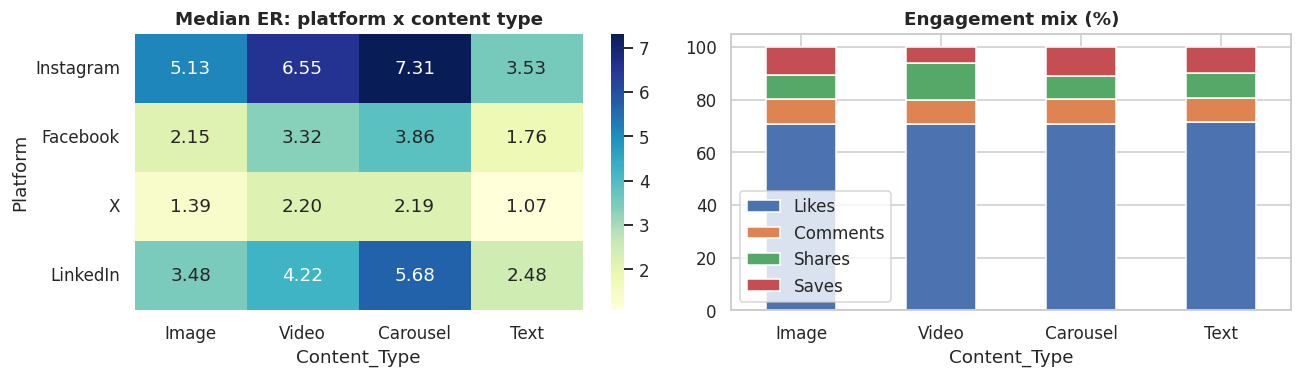

In [6]:
display(seg(df, "Platform").loc[["Instagram", "Facebook", "X", "LinkedIn"]])
tc = seg(df, "Content_Type").loc[["Image", "Video", "Carousel", "Text"]]; display(tc)
pt = v.pivot_table(index="Platform", columns="Content_Type", values="ER", aggfunc="median").reindex(["Instagram", "Facebook", "X", "LinkedIn"])[["Image", "Video", "Carousel", "Text"]]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
sns.heatmap(pt, annot=True, fmt=".2f", cmap="YlGnBu", ax=axs[0]); axs[0].set_title("Median ER: platform x content type")
mix = v.groupby("Content_Type")[["Likes", "Comments", "Shares", "Saves"]].sum(); (mix.div(mix.sum(axis=1), axis=0) * 100).loc[["Image", "Video", "Carousel", "Text"]].plot(kind="bar", stacked=True, ax=axs[1], rot=0); axs[1].set_title("Engagement mix (%)")
plt.tight_layout(); plt.show()

## 5. Timing, hashtags and captions

In [7]:
display(seg(df, "Part").loc[["Late night (0-6)", "Morning (7-11)", "Afternoon (12-17)", "Evening (18-21)", "Night (22-23)"]])
display(seg(df, "Weekday"))
w, wd = v[v.Weekend].ER, v[~v.Weekend].ER; print("Weekend vs weekday median ER: %.2f vs %.2f (Mann-Whitney p = %.3f)" % (w.median(), wd.median(), stats.mannwhitneyu(w, wd).pvalue))

,posts,median_ER,median_reach,engagements,CTR,CI_low,CI_high,share_of_engagements_%
Part,,,,,,,,
Late night (0-6),81,2.29,5356.0,39282,0.86,1.68,2.89,2.51
Morning (7-11),433,3.58,6292.0,398323,0.94,3.17,3.99,25.46
Afternoon (12-17),656,3.67,8416.5,681739,0.92,3.32,3.91,43.57
Evening (18-21),228,4.16,12087.0,349846,0.81,3.47,4.67,22.36
Night (22-23),74,2.99,9953.5,95367,0.82,2.39,3.87,6.10


,posts,median_ER,median_reach,engagements,CTR,CI_low,CI_high,share_of_engagements_%
Weekday,,,,,,,,
Monday,219,3.29,7477.0,196183,0.98,2.80,3.77,12.39
Tuesday,172,3.70,8229.0,211794,0.77,3.06,4.28,13.37
Wednesday,218,3.71,9278.0,237147,0.96,3.34,4.53,14.97
Thursday,207,3.40,8216.0,178996,0.89,2.87,4.04,11.30
Friday,227,3.18,8537.0,229818,0.94,2.61,3.55,14.51
Saturday,224,4.08,8356.5,289870,0.91,3.65,4.60,18.30
Sunday,223,3.45,7134.0,240157,0.83,2.93,4.05,15.16


Weekend vs weekday median ER: 3.86 vs 3.43 (Mann-Whitney p = 0.019)


In [8]:
# Hashtags: the raw comparison across all platforms is confounded by platform (only IG and FB use more than 5 tags)
print("Naive median ER by hashtag band (all platforms):", v.groupby("Hash_Band", observed=True).ER.median().round(2).to_dict())
igfb = df[df.Platform.isin(["Instagram", "Facebook"])]
print("\nWithin Instagram + Facebook:"); display(seg(igfb, "Hash_Band"))
print("Kruskal-Wallis across bands: p = %.2f" % stats.kruskal(*[g.ER.values for _, g in igfb[igfb.Valid].groupby("Hash_Band", observed=True)]).pvalue)
display(seg(df, "Cap_Band"))

Naive median ER by hashtag band (all platforms): {'0': 2.52, '1-2': 2.46, '3-5': 3.22, '6-8': 4.9, '9+': 4.55}

Within Instagram + Facebook:


,posts,median_ER,median_reach,engagements,CTR,CI_low,CI_high,share_of_engagements_%
Hash_Band,,,,,,,,
0,62,4.16,20083.0,86583,0.82,3.22,5.31,5.81
1-2,115,4.05,13828.0,156020,0.99,3.23,4.58,10.48
3-5,188,4.44,14827.5,331538,0.87,4.07,5.13,22.26
6-8,173,4.90,14643.0,252165,0.80,4.18,5.40,16.93
9+,425,4.55,16041.0,662955,0.81,4.16,4.97,44.52


Kruskal-Wallis across bands: p = 0.37


,posts,median_ER,median_reach,engagements,CTR,CI_low,CI_high,share_of_engagements_%
Cap_Band,,,,,,,,
<60,208,3.36,8524.5,198873,0.93,2.64,3.82,12.64
60-150,741,3.68,8144.0,806691,0.88,3.31,3.91,51.26
150-300,486,3.57,7807.5,526094,0.87,3.13,3.92,33.43
300+,45,2.67,8445.0,41998,1.11,2.28,5.40,2.67


## 6. Promotion and campaigns

In [9]:
display(seg(df, "Promoted"))
a, b = v[v.Promoted == "Yes"], v[v.Promoted == "No"]
print("Promoted vs organic reach: %.0f vs %.0f (p = %.1e) | ER: %.2f%% vs %.2f%% (p = %.1e)" % (a.Reach.median(), b.Reach.median(), stats.mannwhitneyu(a.Reach, b.Reach).pvalue, a.ER.median(), b.ER.median(), stats.mannwhitneyu(a.ER, b.ER).pvalue))
display(seg(df, "Campaign").sort_values("median_ER", ascending=False))
g = v[v.Campaign == "Giveaway"]; o = v[v.Campaign != "Giveaway"]
print("Comments as share of engagement: giveaway %.0f%% vs other %.0f%%" % (g.Comments.sum() / g.Engagements.sum() * 100, o.Comments.sum() / o.Engagements.sum() * 100))

,posts,median_ER,median_reach,engagements,CTR,CI_low,CI_high,share_of_engagements_%
Promoted,,,,,,,,
No,1245,3.77,6264.0,980292,0.82,3.54,4.05,61.89
Yes,245,2.54,29905.0,603673,1.17,2.28,3.04,38.11


Promoted vs organic reach: 29905 vs 6264 (p = 6.2e-55) | ER: 2.54% vs 3.77% (p = 2.8e-08)


,posts,median_ER,median_reach,engagements,CTR,CI_low,CI_high,share_of_engagements_%
Campaign,,,,,,,,
Giveaway,91,6.41,7523.0,129650,1.00,5.12,7.57,8.19
Brand Awareness,273,3.83,8505.0,300519,0.77,3.11,4.23,18.97
No campaign,736,3.46,7008.5,579227,0.87,3.17,3.74,36.57
Festive Sale,206,3.20,14228.5,256291,0.92,2.68,3.61,16.18
Product Launch,184,3.17,10627.0,318278,1.02,2.65,4.37,20.09


Comments as share of engagement: giveaway 25% vs other 8%


## 7. Trends and followers

Month           2025-11    2025-12     2026-01     2026-02     2026-03  \
impressions  1968789.00  3167860.0  2423060.00  2810371.00  2777914.00   
median_ER          3.46        3.7        3.46        3.88        3.38   

Month           2026-04     2026-05     2026-06     2026-07     2026-08  \
impressions  1976527.00  2396779.00  3245715.00  2661614.00  2756455.00   
median_ER          2.48        3.45        3.26        3.74        3.99   

Month           2026-09     2026-10  
impressions  3442268.00  2629212.00  
median_ER          3.67        3.18  
Trend (Spearman): impressions p = 0.39, ER p = 0.81


,start,end,growth_pct,new,unfollows,unfollows_per_100_new,reach_vs_new_followers_p
platform,,,,,,,
Instagram,52286,69727,33.36,20577,2850,13.85,0.20
Facebook,38111,40722,6.85,4435,1713,38.62,0.18
X,23986,24314,1.37,1442,1128,78.22,0.21
LinkedIn,15124,21346,41.14,7238,892,12.32,0.67


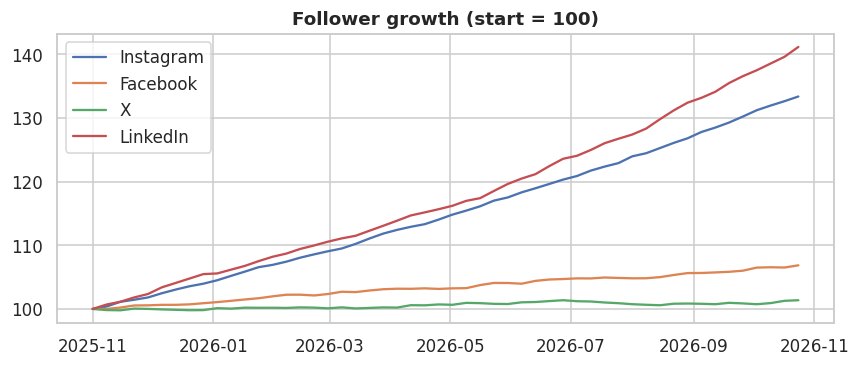

In [10]:
mo = v.groupby("Month").agg(impressions=("Impressions", "sum"), median_ER=("ER", "median"))
print(mo.round(2).T)
print("Trend (Spearman): impressions p = %.2f, ER p = %.2f" % (stats.spearmanr(range(12), mo.impressions)[1], stats.spearmanr(range(12), mo.median_ER)[1]))
rows = []
for pl in ["Instagram", "Facebook", "X", "LinkedIn"]:
    d = fw[fw.Platform == pl].sort_values("Week_Start"); posts = df[df.Platform == pl]
    reach_w = [posts[(posts.Date >= w0) & (posts.Date < w0 + pd.Timedelta(days=7))].Reach.sum() for w0 in d.Week_Start]
    sp = stats.spearmanr(reach_w, d.New_Followers)
    rows.append(dict(platform=pl, start=d.Followers.iloc[0], end=d.Followers.iloc[-1], growth_pct=(d.Followers.iloc[-1] / d.Followers.iloc[0] - 1) * 100, new=d.New_Followers.sum(), unfollows=d.Unfollows.sum(),
                     unfollows_per_100_new=d.Unfollows.sum() / d.New_Followers.sum() * 100, reach_vs_new_followers_p=sp[1]))
display(pd.DataFrame(rows).set_index("platform").round(2))
fig, ax = plt.subplots(figsize=(8, 3.5))
for pl in ["Instagram", "Facebook", "X", "LinkedIn"]:
    d = fw[fw.Platform == pl]; ax.plot(d.Week_Start, d.Followers / d.Followers.iloc[0] * 100, label=pl)
ax.set_title("Follower growth (start = 100)"); ax.legend(); plt.tight_layout(); plt.show()

## 8. What drives engagement? (regression on log ER)

n = 1448, R-squared = 0.63 (baseline: Instagram, image, daytime, weekday, organic, no campaign)


,effect_%,CI_low_%,CI_high_%,p
Video,33.718,24.051,44.138,0.000
Carousel,42.496,31.528,54.379,0.000
Text,-30.405,-35.755,-24.609,0.000
Facebook,-54.078,-57.203,-50.726,0.000
X,-67.806,-70.554,-64.802,0.000
LinkedIn,-26.267,-32.641,-19.290,0.000
Hashtags (per tag up to 5),5.913,4.016,7.844,0.000
Hashtags (per tag above 8),-2.095,-3.586,-0.581,0.007
Evening (18-21),11.827,3.595,20.713,0.004
Late night (0-6),-30.042,-37.938,-21.142,0.000


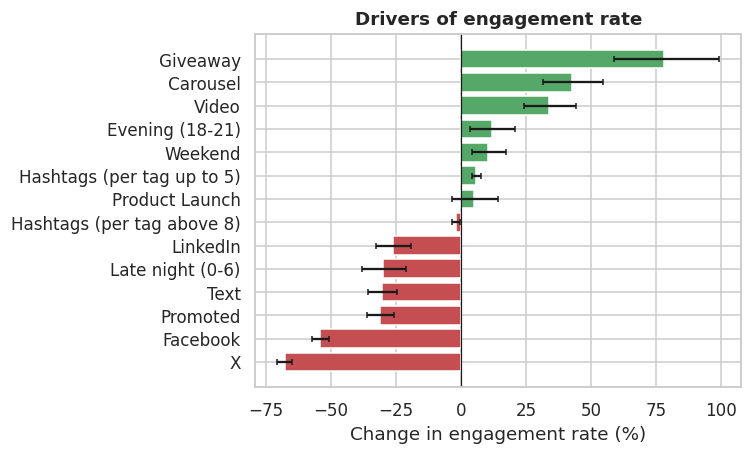

In [11]:
r = v.dropna(subset=["Hour", "Hashtag_Count", "Caption_Length"])
X = pd.DataFrame({"const": 1.0, "Video": (r.Content_Type == "Video") * 1., "Carousel": (r.Content_Type == "Carousel") * 1., "Text": (r.Content_Type == "Text") * 1.,
    "Facebook": (r.Platform == "Facebook") * 1., "X": (r.Platform == "X") * 1., "LinkedIn": (r.Platform == "LinkedIn") * 1.,
    "Hashtags (per tag up to 5)": np.minimum(r.Hashtag_Count, 5), "Hashtags (per tag above 8)": np.maximum(r.Hashtag_Count - 8, 0),
    "Evening (18-21)": (r.Part == "Evening (18-21)") * 1., "Late night (0-6)": (r.Part == "Late night (0-6)") * 1., "Weekend": r.Weekend * 1.,
    "Promoted": (r.Promoted == "Yes") * 1., "Giveaway": (r.Campaign == "Giveaway") * 1., "Product Launch": (r.Campaign == "Product Launch") * 1.})
y = np.log(r.ER.values); A = X.values; beta = np.linalg.lstsq(A, y, rcond=None)[0]; res = y - A @ beta; n, k = A.shape
se = np.sqrt(np.diag(res @ res / (n - k) * np.linalg.inv(A.T @ A))); p = 2 * (1 - stats.t.cdf(abs(beta / se), n - k)); r2 = 1 - res @ res / ((y - y.mean()) @ (y - y.mean()))
out = pd.DataFrame({"effect_%": (np.exp(beta) - 1) * 100, "CI_low_%": (np.exp(beta - 1.96 * se) - 1) * 100, "CI_high_%": (np.exp(beta + 1.96 * se) - 1) * 100, "p": p}, index=X.columns).round(3)
print("n = %d, R-squared = %.2f (baseline: Instagram, image, daytime, weekday, organic, no campaign)" % (n, r2)); display(out.drop("const"))
o = out.drop("const").sort_values("effect_%"); plt.figure(figsize=(7, 4.3)); plt.barh(o.index, o["effect_%"], xerr=[o["effect_%"] - o["CI_low_%"], o["CI_high_%"] - o["effect_%"]], color=["C2" if x > 0 else "C3" for x in o["effect_%"]], capsize=2)
plt.axvline(0, color="k", lw=.8); plt.xlabel("Change in engagement rate (%)"); plt.title("Drivers of engagement rate"); plt.tight_layout(); plt.show()

## 9. Findings and recommendations

| Finding | Evidence |
|---|---|
| Format matters most | median ER carousel 6.09%, video 4.54%, image 3.38%, text 1.62% |
| Instagram carries the account | 40% of posts, 90% of engagements; median ER 6.0% |
| Promotion buys reach, not rate | reach 4.8x, ER about 32% lower (adjusted) |
| Giveaways lift engagement | adjusted +78%; comments 25% of engagement vs 8% |
| Timing helps at the margins | evening +12%, late night -30%, weekend +10% |
| Hashtags and caption length: little effect | band differences not significant within IG and FB (p = 0.37) |
| Results concentrated | top 10% of posts = 55% of engagements |

**Recommendations:** (1) carousels and video by default; (2) separate goals for promoted and organic posts, track cost per engagement; (3) evenings and weekends, avoid 0-6 AM; (4) selective giveaways; (5) about 3-5 hashtags; (6) audit X and Facebook; (7) study the top decile; (8) add spend, conversion and sentiment data.

**Limitations:** simulated data, no spend or conversion data, platform reach definitions differ, X has no saves metric, associations not proof of cause.